# US & Taiwan Semiconductor Supply-Chain Cointegration & Machine Learning Strategy
**Stock Markets Analytics Zoomcamp 2026 — Capstone Project (Attempt 1)**

This end-to-end research and automation notebook executes the complete quantitative workflow by importing and calling the modular `.py` packages in [`src/`](../src/):
1. **Data Sources & Loading (`src.data_loader`)**: Combines daily OHLCV for 23 US-listed semiconductor equities, 4 Taiwanese supply-chain bellwethers (`2330.TW`, `2303.TW`, `2454.TW`, `3711.TW`), sector/market benchmarks (`SOXX`, `SMH`, `^GSPC`, `^VIX`, `TWD=X`, `DX-Y.NYB`), 5 FRED macroeconomic series (`DGS10`, `DGS2`, `T10Y2Y`, `FEDFUNDS`, `BAMLH0A0HYM2`), and **point-in-time quarterly accounting fundamentals from the SEC EDGAR XBRL API**.
2. **Transformations, Cointegration & EDA (`src.transformations`)**: Engineers 28 new domain-specific features (rolling 60-day OLS hedge ratio $\beta_t$, log-price spread $S_t$, 20d/60d Spread Z-Scores $Z_t$, rolling ADF stationarity proxy, Ornstein-Uhlenbeck half-life $\tau$, TSMC ADR premium, Taiwan supply-chain momentum, and SEC EDGAR inventory/revenue ratios), binned regime variables, and seasonal calendar dummies.
3. **Machine Learning & Hyperparameter Tuning (`src.modeling`)**: Compares 4 domain hand-crafted rules with tuned `DecisionTreeClassifier`, `RandomForestClassifier`, `XGBClassifier`, penalized `Ridge` regression, and a 2-layer Deep Neural Network (`MLPClassifier`), culminating in the Cointegration + ML Consensus Hybrid rule.
4. **Trading Simulation & Subgroup Diagnostics (`src.simulation`)**: Evaluates vector simulations (`sim1_` raw and `sim2_` stop-loss/take-profit managed) and an exact chronological `iterrows()` portfolio simulator (`sim3_`) with compounding capital reinvestment, Top-K concurrent position limits, and dynamic position sizing.
5. **Live 10-Day Trade Signals & Broker API (`src.broker_api` & `src.monitor`)**: Produces the latest trade orders for the next 10 trading days with exact share quantities and bracket Stop-Loss / Take-Profit levels.

In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Add Project Attempt 1 root to sys.path so `src` modules import cleanly
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    COMBINED_DATA_PATH, FIGURES_DIR, REPORTS_DIR,
    SUPPLY_CHAIN_PEER_MAP, TARGET_BINARY_COL, TARGET_GROWTH_COL, US_SEMI_TICKERS
)
from src.data_loader import load_or_download_raw_data
from src.transformations import build_unified_dataset, get_feature_sets, run_pair_cointegration_adf_summary
from src.modeling import evaluate_predictions_on_test, tune_and_train_models
from src.simulation import (
    run_deep_exploratory_error_analysis,
    run_exact_iterrows_portfolio_simulation,
    run_vector_simulations,
)
from src.broker_api import generate_latest_live_signals, submit_orders_to_broker
from src.monitor import build_html_monitoring_dashboard, generate_all_charts

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
print(f'Project Root: {PROJECT_ROOT}')

Project Root: C:\Users\muhds\.gemini\antigravity-ide\scratch\Stock-Markets-Analytics-Zoomcamp-2026\Project Attempt 1


## 1. Data Loading & Unified Dataset Construction (`mode='local'` / `'download'`)
We load the unified multi-source dataset combining Yahoo Finance OHLCV (23 US Semi tickers + 4 Taiwan TWSE anchors + ETFs/FX/VIX), FRED macroeconomic yields, and point-in-time SEC EDGAR XBRL fundamentals.

In [2]:
if COMBINED_DATA_PATH.exists():
    df_base = pd.read_parquet(COMBINED_DATA_PATH)
else:
    df_ohlcv, df_ctx, df_sec = load_or_download_raw_data(mode='local', incremental=False)
    df_base = build_unified_dataset(df_ohlcv, df_ctx, df_sec, save_parquet=True)

df_full, feature_sets = get_feature_sets(df_base)
print(f'Unified Dataset Shape: {df_full.shape[0]:,} rows x {df_full.shape[1]} columns')
print('Date Range:', df_full['Date'].min().date(), 'to', df_full['Date'].max().date())
for k, v in feature_sets.items():
    print(f'  Feature Set {k:22s}: {len(v):3d} columns')

df_full[['Date', 'Ticker', 'sub_vertical', 'peer_ticker', 'Close', 'pair_spread_zscore_20d', 'sec_rev_yoy', 'split']].tail(8)

Unified Dataset Shape: 87,715 rows x 195 columns
Date Range: 2011-01-03 to 2026-11-09
  Feature Set TO_PREDICT            :   8 columns
  Feature Set GROWTH                :   9 columns
  Feature Set CUSTOM_NUMERICAL      :  15 columns
  Feature Set TECHNICAL_INDICATORS  :  16 columns
  Feature Set NEW_DOMAIN_FEATURES   :  33 columns
  Feature Set MACRO                 :  21 columns
  Feature Set NUMERIC               :  94 columns
  Feature Set CATEGORICAL           :   6 columns
  Feature Set DUMMIES               :  33 columns
  Feature Set ALL_FEATURES          : 127 columns


,Date,Ticker,sub_vertical,peer_ticker,Close,pair_spread_zscore_20d,sec_rev_yoy,split
87707,2026-11-09,NXPI,Analog_Power_RF,ON,256.420013,0.653852,0.193193,live
87708,2026-11-09,ON,Analog_Power_RF,NXPI,69.110001,-0.092955,0.110516,live
87709,2026-11-09,QCOM,Foundry_Logic,INTC,171.470001,0.046070,-0.026285,live
87710,2026-11-09,SWKS,Analog_Power_RF,QRVO,82.830002,NaN,-0.031295,live
87711,2026-11-09,TER,WFE_Equipment,ENTG,246.000000,-0.929369,0.440361,live
87712,2026-11-09,TSM,Foundry_Logic,ASML,388.619995,-1.121402,2.353813,live
87713,2026-11-09,TXN,Analog_Power_RF,ADI,295.730011,0.937398,0.276887,live
87714,2026-11-09,WDC,Memory_Storage,MU,289.779999,1.288949,0.554649,live


## 2. Exploratory Data Analysis (EDA) & Supply-Chain Cointegration Verification
We test all semiconductor sub-vertical supply-chain pairs for stationarity using the Augmented Dickey-Fuller (ADF) test on the rolling cointegrated log-price spread $S_t = \ln(P_{A,t}) - (\alpha_t + \beta_t \ln(P_{B,t}))$, and examine feature correlations with the 10-trading-day forward return target.

In [3]:
df_coint_adf = run_pair_cointegration_adf_summary(df_full)
display(df_coint_adf)

# Target distribution summary by temporal split
split_summary = (
    df_full.groupby('split')
    .agg(
        Records=('Ticker', 'count'),
        Min_Date=('Date', 'min'),
        Max_Date=('Date', 'max'),
        Positive_10d_Rate=(TARGET_BINARY_COL, 'mean'),
        Mean_10d_Growth=(TARGET_GROWTH_COL, 'mean'),
    )
    .reset_index()
)
display(split_summary)

,Pair,Sub_Vertical,ADF_Statistic,ADF_p_value,Is_Stationary_p05,Median_60d_Return_Corr,Median_HalfLife_Days,Observations
0,LRCX / AMAT,WFE_Equipment,-11.3226,0.0,True,0.8538,6.07,3987
1,AVGO / MRVL,Foundry_Logic,-10.7927,0.0,True,0.5305,5.68,3987
2,MU / WDC,Memory_Storage,-10.4428,0.0,True,0.6275,6.03,3987
3,ASML / TSM,WFE_Equipment,-10.4407,0.0,True,0.5901,5.04,3987
4,KLAC / ASML,WFE_Equipment,-10.3784,0.0,True,0.7193,5.98,3987
5,MCHP / MPWR,Analog_Power_RF,-10.3154,0.0,True,0.6929,6.63,3987
6,TXN / ADI,Analog_Power_RF,-10.1795,0.0,True,0.8132,5.95,3987
7,NVDA / AMD,Foundry_Logic,-9.5858,0.0,True,0.5530,6.29,3987
8,NXPI / ON,Analog_Power_RF,-9.4613,0.0,True,0.7168,5.32,3987
9,QCOM / INTC,Foundry_Logic,-8.9778,0.0,True,0.4679,7.26,3987


,split,Records,Min_Date,Max_Date,Positive_10d_Rate,Mean_10d_Growth
0,live,221,2026-10-02,2026-11-09,0.000000,NaN
1,test,13090,2024-06-12,2026-10-26,0.539496,1.015017
2,train,61314,2011-01-03,2022-01-27,0.570408,1.010600
3,validation,13090,2022-01-28,2024-06-11,0.528037,1.009991


In [4]:
# Top 15 numerical features correlated with 10-day positive future growth
num_cols = feature_sets['NUMERIC']
corrs = df_full[num_cols].apply(lambda s: s.corr(df_full[TARGET_BINARY_COL])).dropna()
df_corr = pd.DataFrame({
    'Feature': corrs.index,
    'Correlation': corrs.values,
    'Abs_Correlation': corrs.abs().values
}).sort_values('Abs_Correlation', ascending=False).head(15).reset_index(drop=True)
display(df_corr)

,Feature,Correlation,Abs_Correlation
0,vix_close,0.064155,0.064155
1,vix_high_regime,0.053332,0.053332
2,dgs10,-0.051580,0.051580
3,tw_ase_ret_10d,-0.049866,0.049866
4,sp500_ret_20d,-0.036989,0.036989
5,cmf_20,-0.036474,0.036474
6,dgs2,-0.036170,0.036170
7,pair_corr_60d,0.034896,0.034896
8,dgs10_diff_20d,-0.034295,0.034295
9,hy_oas_spread,0.031038,0.031038


## 3. Machine Learning Modeling, Hyperparameter Tuning & Out-of-Sample Precision
We evaluate 4 manual domain rules (`pred0`..`pred3`) alongside tuned `DecisionTreeClassifier`, `RandomForestClassifier`, `XGBClassifier`, penalized `Ridge` regression, and a Deep Neural Network (`MLPClassifier`), plus probability threshold rules and the Cointegration + ML Consensus Hybrid strategy (`pred12_coint_ml_hybrid`).

In [5]:
df_full, models_dict, df_tuning, df_feat_imp = tune_and_train_models(df_full, feature_sets['ALL_FEATURES'])
print('Hyperparameter Tuning Results on Temporal Validation Split:')
display(df_tuning)

print('Top 15 Most Important Features (Random Forest & XGBoost Combined):')
display(df_feat_imp.head(15))

[Modeling] Generating manual heuristic trading rules...


[Modeling] Tuning DecisionTreeClassifier across max_depth in [2, 3, 4, 5, 6, 8, 10]...


[Modeling] Tuning RandomForestClassifier across max_depth and min_samples_leaf...


[Modeling] Tuning & fitting XGBClassifier (Gradient Boosted Trees)...


[Modeling] Fitting penalized Ridge Regression for continuous 10-day return prediction...


[Modeling] Fitting Deep Neural Network (MLPClassifier 2-layer architecture)...


Hyperparameter Tuning Results on Temporal Validation Split:


,Model_Family,Hyperparameters,Val_Precision,Val_Accuracy,Val_ROC_AUC,Positive_Calls_Val
0,DecisionTree,"max_depth=2, min_samples_leaf=50",0.3873,0.4443,0.4526,1606
1,DecisionTree,"max_depth=3, min_samples_leaf=50",0.4841,0.4655,0.4702,2640
2,DecisionTree,"max_depth=4, min_samples_leaf=50",0.5045,0.4744,0.4549,3578
3,DecisionTree,"max_depth=5, min_samples_leaf=50",0.5126,0.4798,0.4588,4040
4,DecisionTree,"max_depth=6, min_samples_leaf=50",0.5193,0.4846,0.4630,4296
5,DecisionTree,"max_depth=8, min_samples_leaf=50",0.5266,0.4885,0.4625,4054
6,DecisionTree,"max_depth=10, min_samples_leaf=50",0.5469,0.4998,0.4830,3878
7,RandomForest,"max_depth=4, min_samples_leaf=50",0.4410,0.4449,0.4581,2510
8,RandomForest,"max_depth=6, min_samples_leaf=40",0.4569,0.4374,0.4666,2388
9,RandomForest,"max_depth=8, min_samples_leaf=30",0.4440,0.4378,0.4659,2642


Top 15 Most Important Features (Random Forest & XGBoost Combined):


,Feature,RF_Importance,XGB_Importance,DT_Importance,Combined_Importance
0,dgs10,0.074459,0.020326,0.120302,0.047393
1,dgs2,0.065098,0.019242,0.070125,0.042170
2,fedfunds,0.044635,0.021123,0.041255,0.032879
3,t10y2y,0.049676,0.014592,0.050121,0.032134
4,dgs10_diff_20d,0.045297,0.015929,0.061998,0.030613
5,Month_September,0.030277,0.027049,0.021047,0.028663
6,tw_ase_ret_10d,0.039961,0.015044,0.050726,0.027502
7,soxx_etf_ret_20d,0.037441,0.015474,0.033868,0.026458
8,vix_close,0.038256,0.013782,0.037413,0.026019
9,Month_April,0.024906,0.022919,0.022563,0.023913


In [6]:
df_test_eval = evaluate_predictions_on_test(df_full)
print('Out-of-Sample TEST Split Precision & Return Summary Across All 13 Predictors:')
display(df_test_eval)

Out-of-Sample TEST Split Precision & Return Summary Across All 13 Predictors:


,Prediction_Rule,Test_Positive_Trades,True_Positives,False_Positives,Test_Precision,Test_Accuracy,Test_F1,Mean_10d_Return_Pct,Median_10d_Return_Pct,Mean_10d_Alpha_vs_SOXX_Pct
0,pred11_ensemble_consensus,2213,1313,900,0.5933,0.4921,0.2831,2.530,2.645,0.654
1,pred12_coint_ml_hybrid,1651,978,673,0.5924,0.4838,0.2245,2.267,2.145,0.864
2,pred8_mlp_dnn,2577,1519,1058,0.5894,0.4957,0.3152,2.575,2.477,0.614
3,pred0_manual_coint_zscore,1433,812,621,0.5666,0.4751,0.1912,1.643,1.193,0.524
4,pred1_manual_tw_lead_lag,2114,1181,933,0.5587,0.4794,0.2574,1.762,1.172,0.408
5,pred7_ridge_reg,4227,2330,1897,0.5512,0.4936,0.4128,1.412,1.298,0.452
6,pred3_manual_macro_yield,2804,1539,1265,0.5489,0.4814,0.3120,1.673,1.139,0.409
7,pred6_xgb,8914,4813,4101,0.5399,0.5149,0.6025,1.293,0.911,0.280
8,pred10_xgb_high_prob_58,7961,4263,3698,0.5355,0.5037,0.5675,1.202,0.838,0.246
9,pred2_manual_rsi_vix_filter,1494,799,695,0.5348,0.4684,0.1868,0.842,0.812,0.245


## 4. Trading Strategy Simulations (`sim1_`, `sim2_`, and Exact `iterrows()` Portfolio `sim3_`)
We compare:
- **Strategy 1 (`sim1_`)**: Unfiltered 10-day vector simulation ($1,000 per signal, 0.20% round-trip cost).
- **Strategy 2 (`sim2_`)**: Risk-managed vector simulation with tail Stop-Loss (`-9%`) and Take-Profit (`+16%`).
- **Strategy 3 (`sim3_`)**: Exact chronological `iterrows()` portfolio simulation starting with **$50,000** capital, compounding gains across up to 6 concurrent positions sized by ML conviction and inverse volatility.

In [7]:
df_full, df_sim_summary = run_vector_simulations(df_full)
display(df_sim_summary)

[Simulation] Running vector simulations (sim1_ baseline and sim2_ risk-managed) across all predictors...


,Strategy_Predictor,Test_Trades,Avg_Trades_Per_Active_Day,Q75_Daily_Trades,Required_Capital_USD,Sim1_Gross_Rev_USD,Sim1_Fees_USD,Sim1_Net_Rev_USD,Sim1_Win_Rate_Pct,Sim1_CAGR,Sim1_Annual_Return_Pct,Sim1_Sharpe,Sim2_RiskManaged_Net_Rev_USD,Sim2_Win_Rate_Pct,Sim2_CAGR,Sim2_Annual_Return_Pct,Sim2_Sharpe
0,pred8_mlp_dnn,2577,6.39,9.0,90000.0,66354.67,-5154.0,61200.67,58.21,1.2446,24.46,0.712,82961.21,58.21,1.3172,31.72,1.044
1,pred12_coint_ml_hybrid,1651,4.40,6.0,60000.0,37427.56,-3302.0,34125.56,58.15,1.2091,20.91,0.670,48053.71,58.15,1.2816,28.16,1.048
2,pred11_ensemble_consensus,2213,6.43,9.0,90000.0,55983.28,-4426.0,51557.28,58.52,1.2105,21.05,0.631,71031.95,58.52,1.2781,27.81,0.946
3,pred0_manual_coint_zscore,1433,2.71,4.0,40000.0,23537.34,-2866.0,20671.34,55.48,1.1921,19.21,0.701,31501.84,55.48,1.2776,27.76,1.224
4,pred6_xgb,8914,17.04,22.0,220000.0,115279.15,-17828.0,97451.15,53.11,1.1673,16.73,0.625,166862.52,53.11,1.2688,26.88,1.222
5,pred4_clf_dt_best,10532,21.67,22.0,220000.0,94971.10,-21064.0,73907.10,51.82,1.1299,12.99,0.453,161702.24,51.82,1.2616,26.16,1.163
6,pred3_manual_macro_yield,2804,6.40,9.0,90000.0,46905.05,-5608.0,41297.05,54.03,1.1727,17.27,0.780,58940.40,54.03,1.2367,23.67,1.215
7,pred10_xgb_high_prob_58,7961,15.92,22.0,220000.0,95716.03,-15922.0,79794.03,52.64,1.1394,13.94,0.535,143960.46,52.64,1.2365,23.65,1.103
8,pred5_rf_best,9461,17.65,22.0,220000.0,84479.61,-18922.0,65557.61,50.92,1.1163,11.63,0.417,141651.20,50.92,1.2332,23.32,1.031
9,pred1_manual_tw_lead_lag,2114,6.29,8.0,80000.0,37241.79,-4228.0,33013.79,55.01,1.1569,15.69,0.705,45707.14,55.01,1.2100,21.00,1.076


In [8]:
df_equity, df_trades, portfolio_metrics = run_exact_iterrows_portfolio_simulation(
    df_full,
    signal_col='pred12_coint_ml_hybrid',
)
print('Exact Chronological iterrows() Portfolio Simulation Metrics vs SOXX & S&P 500 Benchmarks:')
display(pd.DataFrame([portfolio_metrics]).T.rename(columns={0: 'Value'}))

print('Sample of Executed Portfolio Trades on Test Set:')
display(df_trades.tail(10))

[Simulation] Running exact chronological iterrows() simulation for `pred12_coint_ml_hybrid`...


Exact Chronological iterrows() Portfolio Simulation Metrics vs SOXX & S&P 500 Benchmarks:


,Value
Initial_Capital_USD,50000.0
Test_Period_Start,2024-06-12
Test_Period_End,2026-10-26
Test_Duration_Years,2.37
Total_Executed_Trades,257
Trade_Win_Rate_Pct,55.64
Avg_Net_Return_Per_Trade_Pct,1.87
Avg_Capital_Utilization_Pct,70.59
Strategy_Final_Equity_USD,121260.93
Strategy_Total_Return_Pct,142.52


Sample of Executed Portfolio Trades on Test Set:


,entry_date,exit_day_idx,Ticker,sub_vertical,direction,invested_usd,prob_ensemble,pair_zscore_20d,gross_return_pct,net_return_pct,exit_date,proceeds_usd,profit_usd
247,2026-09-02,567,MPWR,Analog_Power_RF,LONG,15009.789020,0.555304,-1.887214,-0.040825,-0.042825,2026-09-17,14366.999814,-642.789207
248,2026-10-09,593,TSM,Foundry_Logic,LONG,23994.659651,0.542267,-1.339611,-0.076769,-0.078769,2026-10-23,22104.633166,-1890.026485
249,2026-10-12,594,MU,Memory_Storage,LONG,18255.450294,0.584662,-2.116343,-0.090000,-0.092000,2026-10-26,16575.948867,-1679.501427
250,2026-10-14,594,WDC,Memory_Storage,LONG,20514.525414,0.604075,-1.763182,0.088767,0.086767,2026-10-26,22294.505977,1779.980563
251,2026-10-14,594,MCHP,Analog_Power_RF,LONG,20217.484690,0.551794,-0.319555,0.117614,0.115614,2026-10-26,22554.908895,2337.424205
252,2026-10-15,594,AVGO,Foundry_Logic,LONG,27038.589611,0.723414,-0.531745,0.001946,-0.000054,2026-10-26,27037.125387,-1.464224
253,2026-10-15,594,INTC,Foundry_Logic,LONG,12053.077374,0.522499,-2.619611,-0.034602,-0.036602,2026-10-26,11611.909345,-441.168029
254,2026-10-23,594,ASML,WFE_Equipment,LONG,23333.183753,0.641480,-2.013909,-0.090000,-0.092000,2026-10-26,21186.530847,-2146.652905
255,2026-10-26,594,LRCX,WFE_Equipment,LONG,23898.508153,0.791404,-1.454153,-0.090000,-0.092000,2026-10-26,21699.845403,-2198.662750
256,2026-10-26,594,ASML,WFE_Equipment,LONG,25096.320553,0.722287,-1.603380,-0.090000,-0.092000,2026-10-26,22787.459062,-2308.861491


## 5. Deep Exploratory Analysis & False-Positive Error Debugging
We inspect strategy performance across semiconductor sub-verticals (`Memory_Storage`, `WFE_Equipment`, `Foundry_Logic`, `Analog_Power_RF`), individual tickers, and Cointegration Spread Z-Score regimes, and diagnose the worst False Positive trades on the Test set.

In [9]:
deep_analysis = run_deep_exploratory_error_analysis(df_full, signal_col='pred12_coint_ml_hybrid')
print('1. Performance Breakdown by Semiconductor Sub-Vertical:')
display(deep_analysis['by_subvertical'])

print('2. Performance Breakdown by Cointegration Z-Score Regime:')
display(deep_analysis['by_zscore_regime'])

print('3. Top 10 Tickers by Risk-Managed 10-Day Return:')
display(deep_analysis['by_ticker'].head(10))

print('4. Diagnostic Table of Worst False Positive Predictions on Test Split:')
display(deep_analysis['worst_false_positives'].head(8))

1. Performance Breakdown by Semiconductor Sub-Vertical:


,sub_vertical,Trades,Precision,Mean_10d_Ret_Pct,Managed_10d_Ret_Pct
2,Memory_Storage,163,0.582822,1.920493,4.403557
1,Foundry_Logic,582,0.597938,2.555894,3.104131
0,Analog_Power_RF,389,0.588689,2.605818,3.055740
3,WFE_Equipment,517,0.591876,1.795981,2.751460


2. Performance Breakdown by Cointegration Z-Score Regime:


,zscore_regime_bin,Total_Obs,Base_Positive_Rate,Base_Mean_10d_Ret_Pct,Strategy_Calls,Strategy_Precision
0,Deep_Underval,1642,0.563337,1.542015,493,0.588235
1,Equilibrium,3566,0.526640,1.369210,374,0.582888
2,Extended_Overval,1673,0.552301,2.225148,0,NaN
3,Mild_Overval,3042,0.524326,1.180940,0,NaN
4,Mild_Underval,3167,0.549416,1.555901,784,0.599490


3. Top 10 Tickers by Risk-Managed 10-Day Return:


,Ticker,sub_vertical,peer_ticker,Trades,Precision,Mean_10d_Ret_Pct,Managed_10d_Ret_Pct,Avg_Spread_ZScore,Avg_Ensemble_Prob
6,INTC,Foundry_Logic,QCOM,54,0.648148,8.024143,9.931616,-1.102720,0.634547
12,MU,Memory_Storage,WDC,101,0.584158,3.416431,5.909090,-1.087487,0.700802
17,TER,WFE_Equipment,ENTG,102,0.676471,3.880630,5.196619,-1.242136,0.688359
19,TXN,Analog_Power_RF,ADI,37,0.648649,4.948219,5.055164,-0.823958,0.707042
11,MRVL,Foundry_Logic,AVGO,78,0.576923,3.553765,4.625263,-1.146208,0.662798
13,NVDA,Foundry_Logic,AMD,99,0.616162,3.995926,3.903854,-0.973564,0.681562
10,MPWR,Analog_Power_RF,MCHP,93,0.645161,3.856763,3.858737,-1.187496,0.675534
5,ENTG,WFE_Equipment,TER,58,0.551724,1.463607,3.653396,-1.224952,0.675831
15,ON,Analog_Power_RF,NXPI,62,0.532258,3.171223,3.570326,-1.012713,0.691694
9,MCHP,Analog_Power_RF,MPWR,64,0.546875,1.655995,3.263030,-1.246498,0.675023


4. Diagnostic Table of Worst False Positive Predictions on Test Split:


,Date,Ticker,sub_vertical,peer_ticker,prob_ensemble,pair_spread_zscore_20d,pair_adf_stat_proxy_60d,vix_close,dgs10_diff_20d,rsi_14,sec_rev_yoy,growth_future_10d,future_max_dd_10d,Realized_10d_Return_Pct
75136,2024-07-31,INTC,Foundry_Logic,QCOM,0.783135,-1.291498,-1.407311,16.360001,-0.27,40.790868,0.086129,0.652126,-0.383230,-34.787362
78699,2025-03-25,ENTG,WFE_Equipment,TER,0.746893,-1.155242,-2.514386,17.150000,0.01,41.267231,2.990205,0.667799,-0.355232,-33.220134
75114,2024-07-30,INTC,Foundry_Logic,QCOM,0.646743,-1.501428,-1.576509,17.690001,-0.28,35.944296,0.086129,0.683699,-0.370743,-31.630091
87447,2026-10-22,TER,WFE_Equipment,ENTG,0.773354,-1.119079,-1.731207,19.030001,-0.22,32.907272,0.440361,0.689036,-0.314559,-31.096354
85701,2026-07-01,MRVL,Foundry_Logic,AVGO,0.714063,-1.875831,-1.193307,16.590000,-0.01,52.493512,0.275682,0.692323,-0.315582,-30.767701
78706,2025-03-25,MU,Memory_Storage,WDC,0.810023,-0.687233,-2.167486,17.150000,0.01,47.328567,0.382727,0.696808,-0.345720,-30.319243
78671,2025-03-21,WDC,Memory_Storage,MU,0.692081,-0.135037,-1.140946,19.280001,-0.17,42.155996,0.413259,0.699496,-0.318369,-30.050389
78693,2025-03-24,WDC,Memory_Storage,MU,0.589752,0.034733,-1.035747,17.480000,-0.06,44.809419,0.413259,0.703227,-0.349357,-29.677277


## 6. Visualizations & Latest Live 10-Day Trade Signals
We render all 5 analytical charts and display the latest live 10-day trade signals and simulated Alpaca bracket orders for the upcoming 2-week holding horizon.

[Monitor] Generated 5 analytical charts in C:\Users\muhds\.gemini\antigravity-ide\scratch\Stock-Markets-Analytics-Zoomcamp-2026\Project Attempt 1\outputs\figures.


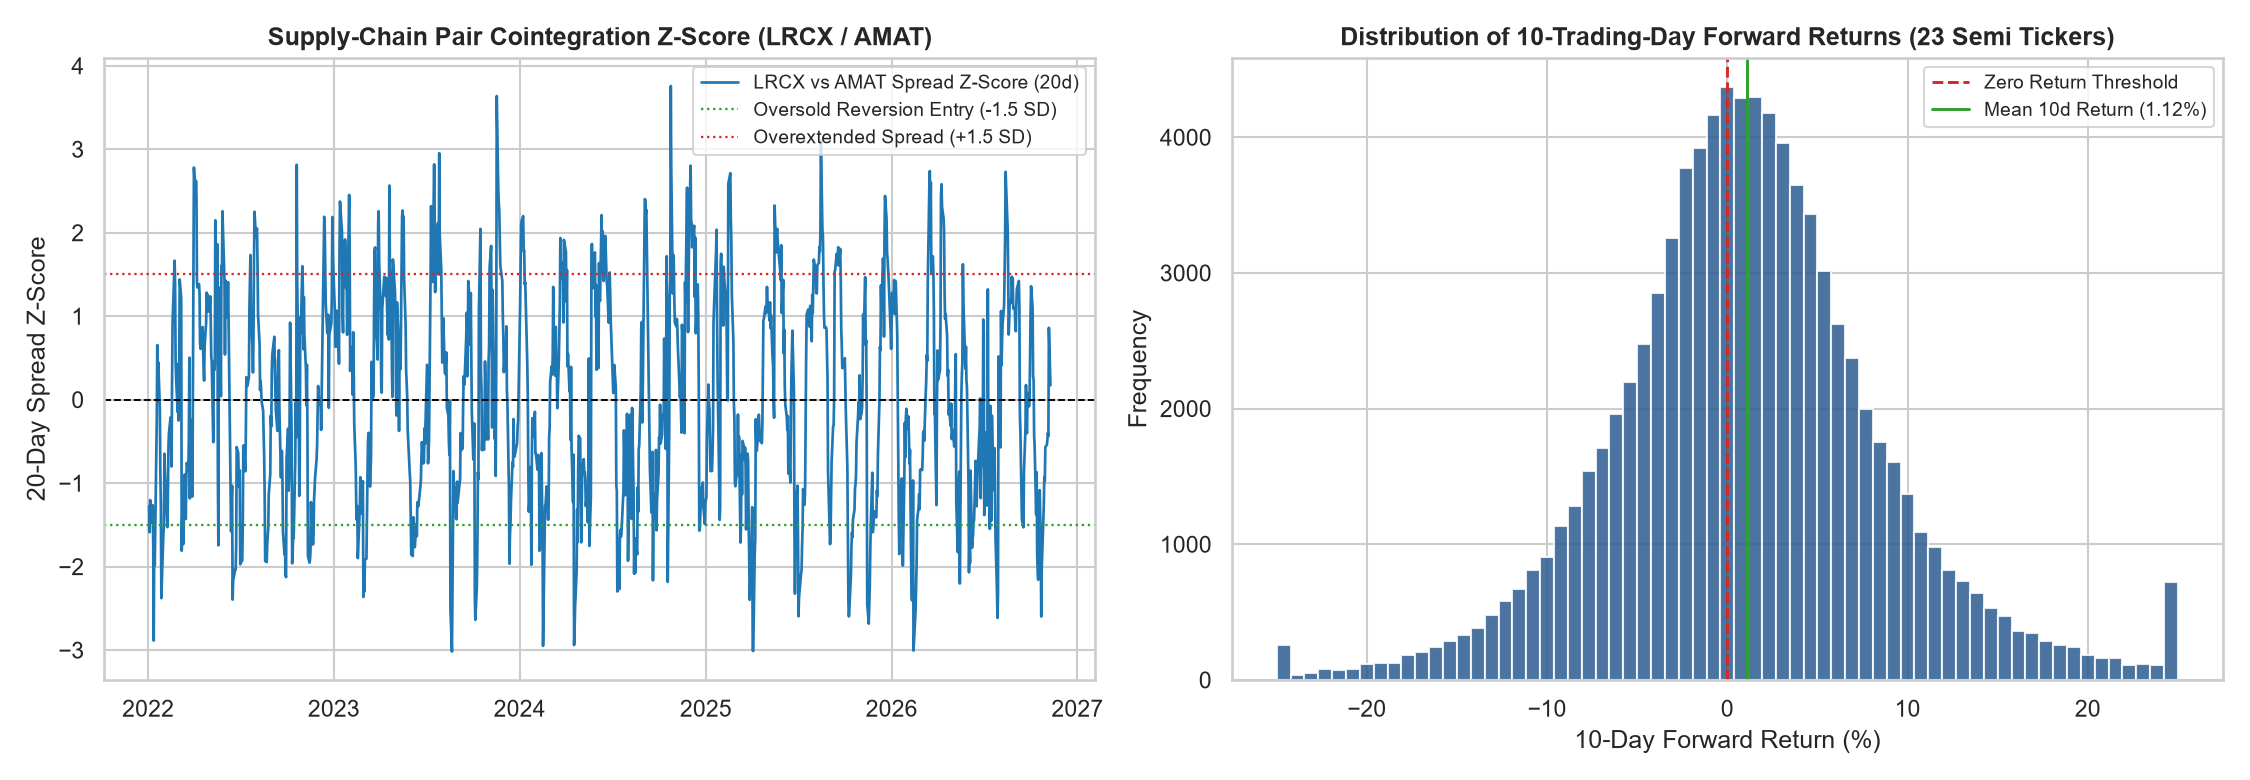

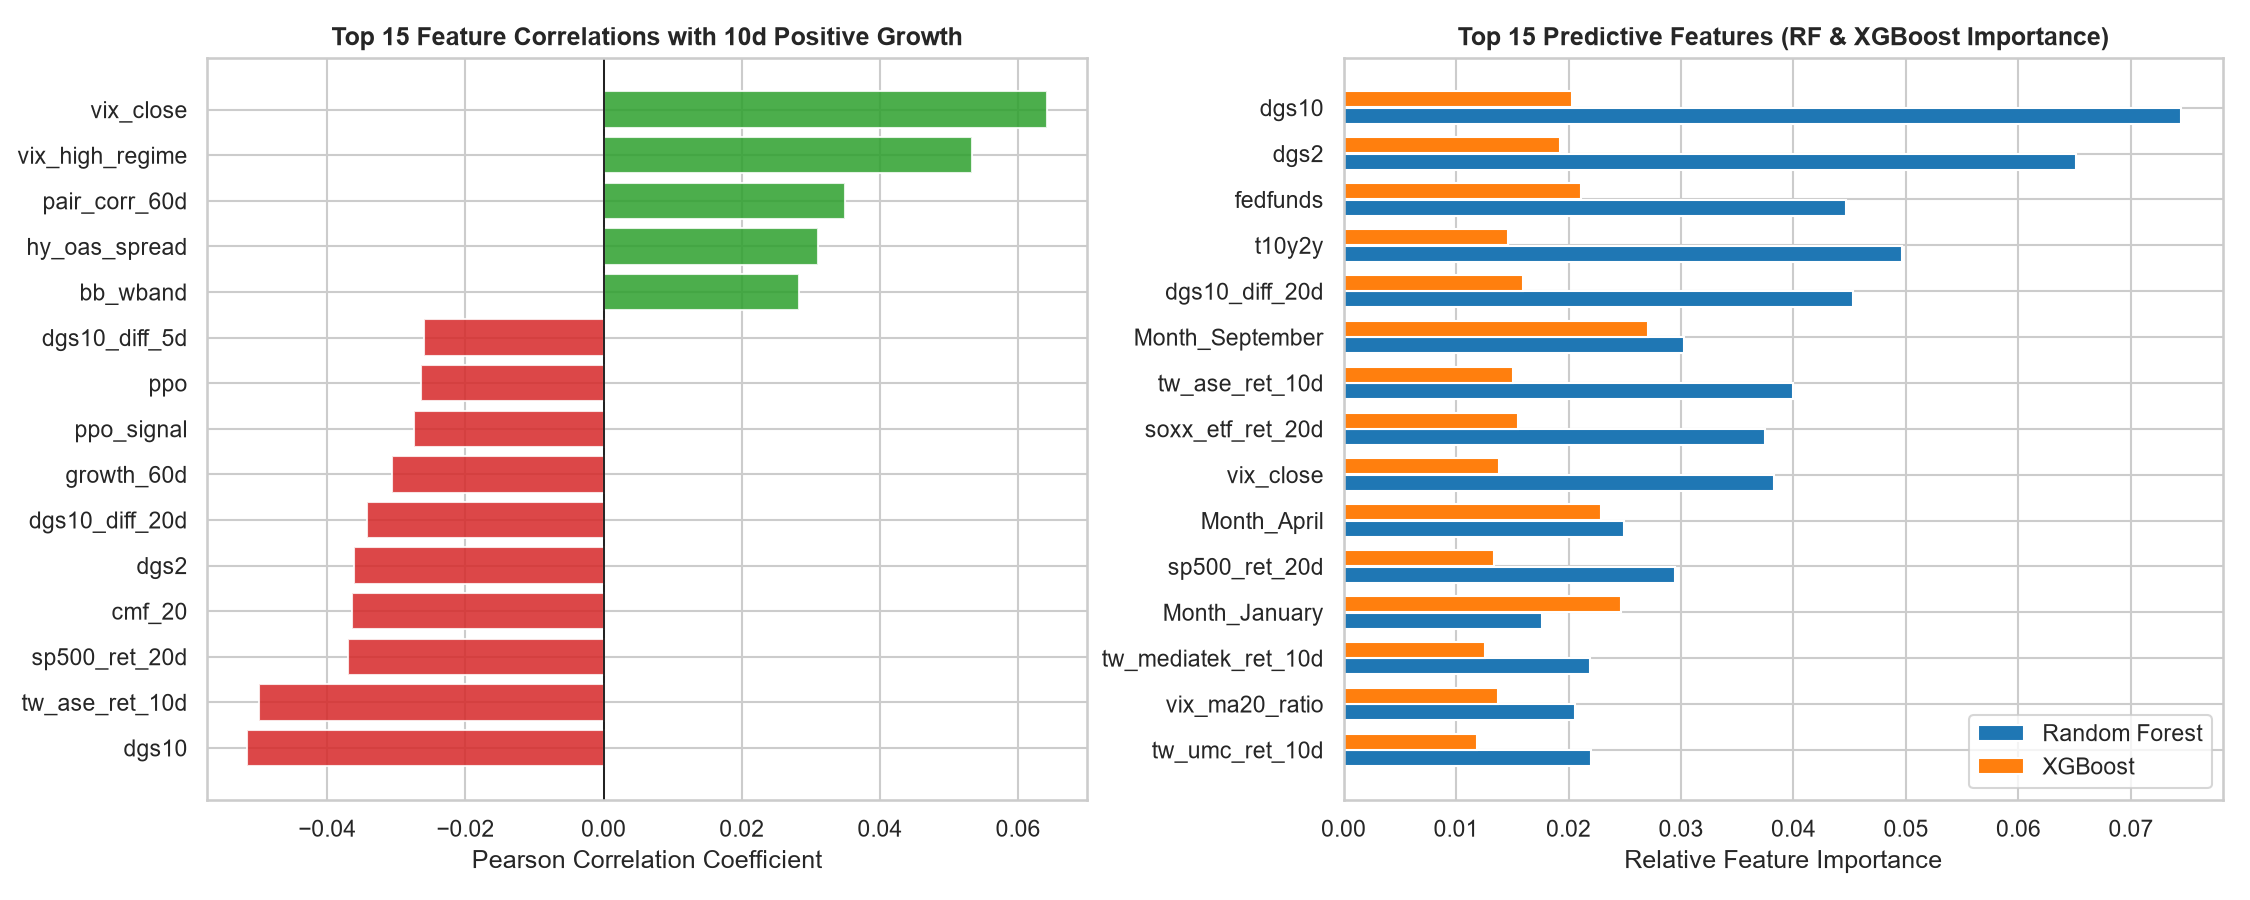

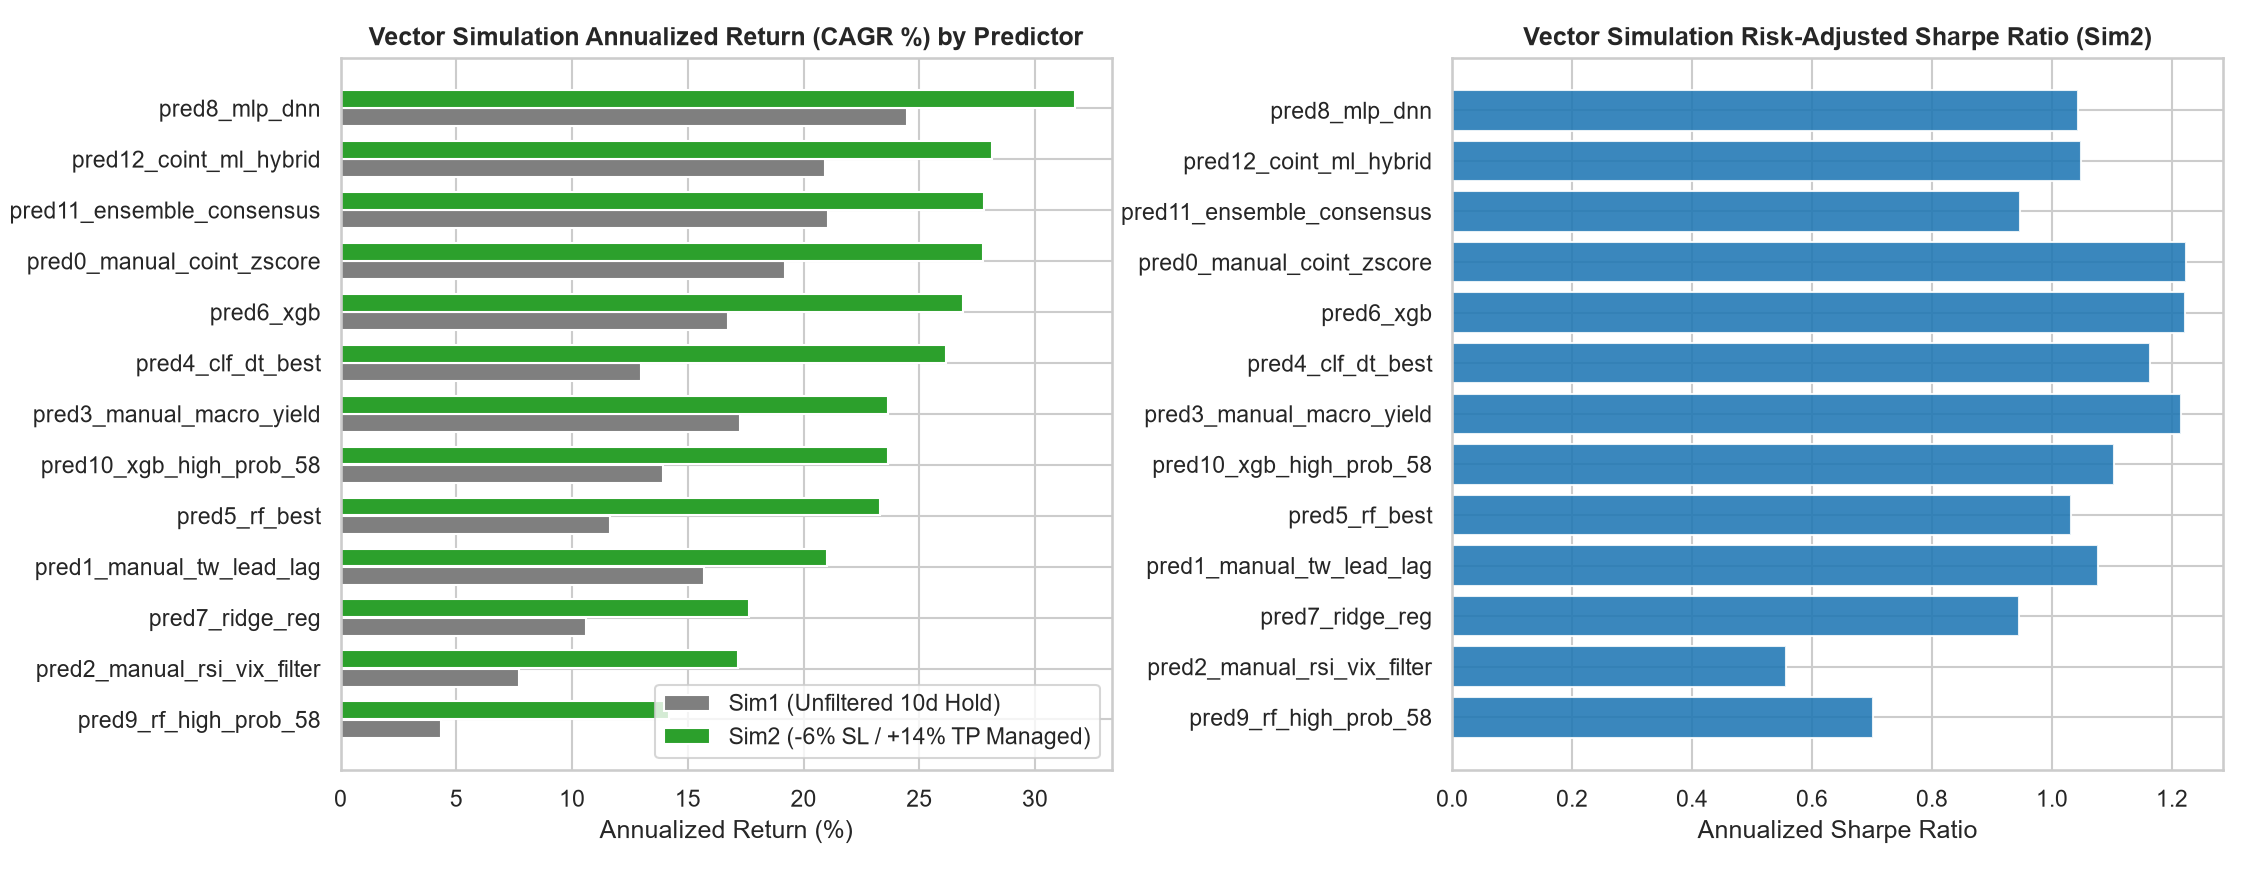

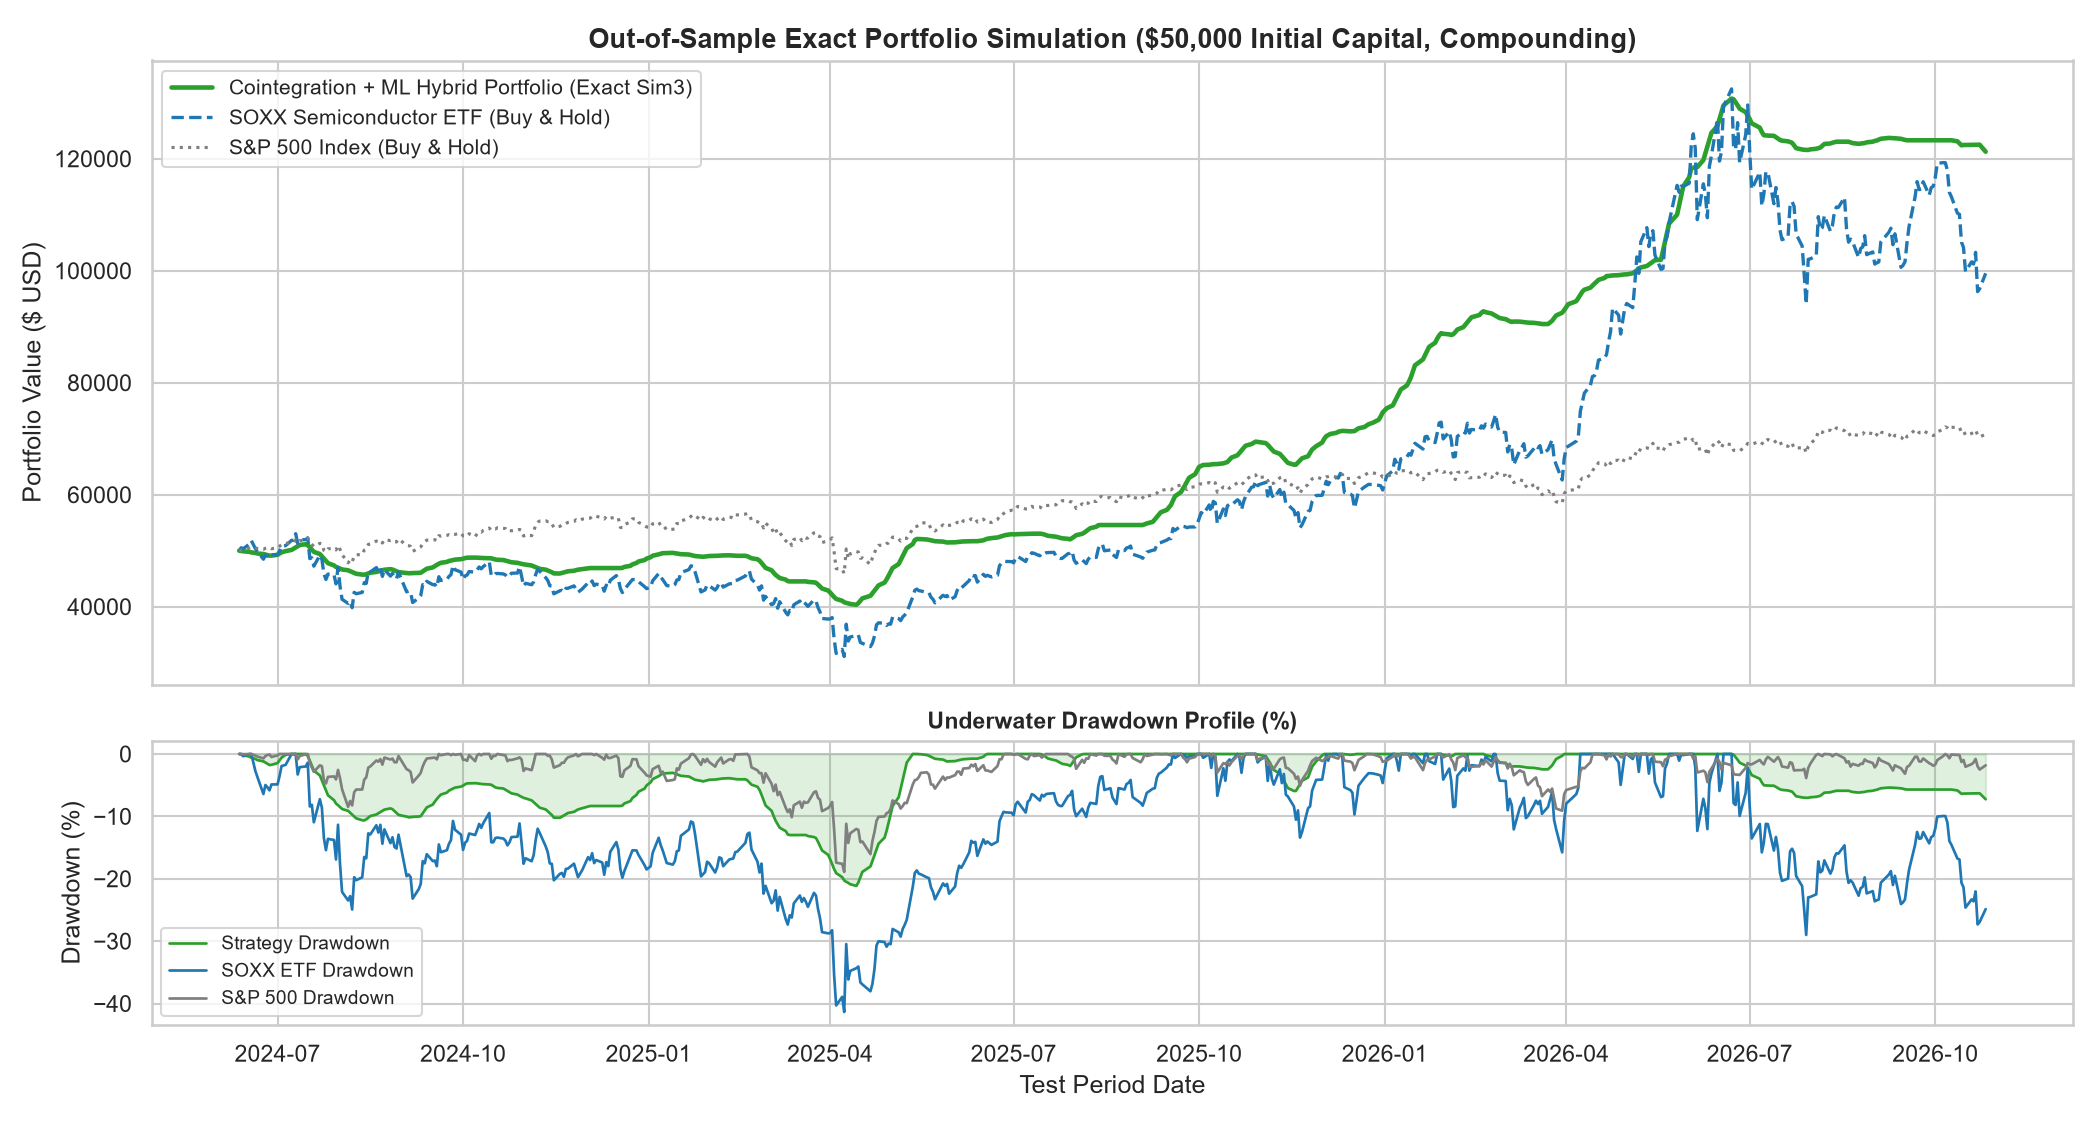

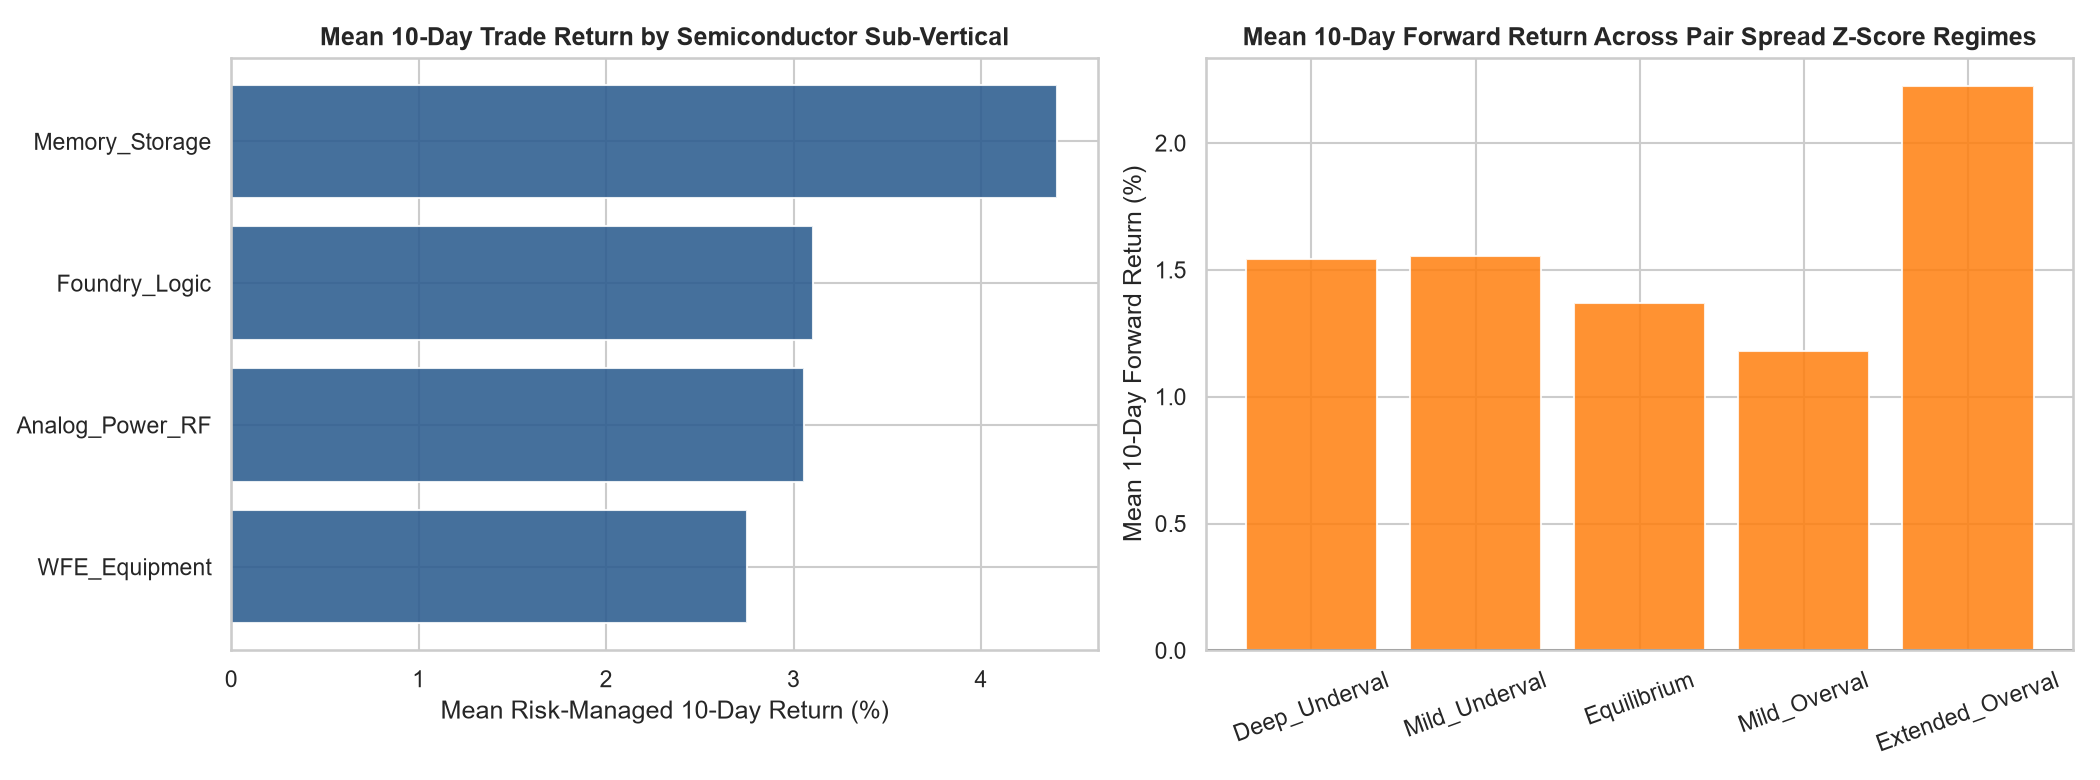

In [10]:
chart_paths = generate_all_charts(df_full, df_feat_imp, df_sim_summary, df_equity, deep_analysis)
for cp in chart_paths:
    display(Image(filename=str(cp)))

In [11]:
df_signals = generate_latest_live_signals(df_full)
broker_orders = submit_orders_to_broker(df_signals, dry_run=True)
dashboard_path = build_html_monitoring_dashboard(portfolio_metrics, df_signals, df_sim_summary, df_coint_adf)

print('Latest Live 10-Trading-Day Rankings & Recommended Bracket Orders:')
display(df_signals.head(12))

print(f'Logged {len(broker_orders)} simulated Alpaca bracket orders:')
print(json.dumps(broker_orders[:3], indent=2))

[BrokerAPI] Saved latest 10-day trade rankings (2026-11-09) to latest_10d_trade_signals.csv.
[BrokerAPI] Logged 6 bracket order(s) to paper_broker_orders.json.
[Monitor] Built interactive HTML monitoring dashboard at monitoring_dashboard.html.
Latest Live 10-Trading-Day Rankings & Recommended Bracket Orders:


,Date,Ticker,sub_vertical,peer_ticker,Close,prob_rf,prob_xgb,prob_mlp,prob_ensemble,pred_reg_growth_10d,pair_spread_zscore_20d,pair_adf_stat_proxy_60d,tw_supply_chain_index_10d,sec_rev_yoy,conviction_score,Recommended_Action,Allocated_Capital_USD,Order_Shares,Stop_Loss_Price,Take_Profit_Price
0,2026-11-09,NVDA,Foundry_Logic,AMD,178.669998,0.653136,0.880412,0.960597,0.801212,1.034874,-3.012768,0.543772,-0.126412,0.080000,1.028571,BUY_LONG_10D,10416.67,58,162.59,207.26
1,2026-11-09,MCHP,Analog_Power_RF,MPWR,61.500000,0.647194,0.865676,0.987486,0.806358,1.028249,-2.582802,-0.083146,-0.126412,0.421870,1.000341,BUY_LONG_10D,10416.67,169,55.97,71.34
2,2026-11-09,TSM,Foundry_Logic,ASML,388.619995,0.663314,0.878488,0.999839,0.818367,1.035185,-1.121402,-1.618424,-0.126412,2.353813,0.895438,BUY_LONG_10D,10416.67,26,353.64,450.80
3,2026-11-09,INTC,Foundry_Logic,QCOM,59.369999,0.687719,0.876154,0.909114,0.786258,1.058807,-1.349972,-0.173794,-0.126412,0.209478,0.881614,BUY_LONG_10D,10416.67,175,54.03,68.87
4,2026-11-09,ENTG,WFE_Equipment,TER,140.059998,0.656556,0.880014,0.997404,0.816499,1.021809,-0.904047,-1.812251,-0.126412,0.246066,0.876182,BUY_LONG_10D,10416.67,74,127.45,162.47
5,2026-11-09,ADI,Analog_Power_RF,TXN,394.660004,0.662791,0.871145,0.995148,0.814183,1.013883,-0.834400,-0.910527,-0.126412,0.396324,0.868294,BUY_LONG_10D,10416.67,26,359.14,457.81
6,2026-11-09,TER,WFE_Equipment,ENTG,246.000000,0.676919,0.891072,0.951381,0.805480,1.043146,-0.929369,0.432815,-0.126412,0.440361,0.867188,HOLD_WAIT,0.00,0,223.86,285.36
7,2026-11-09,MRVL,Foundry_Logic,AVGO,154.600006,0.684969,0.889755,0.867362,0.773087,1.052291,-0.940107,-0.893929,-0.126412,0.365485,0.835655,HOLD_WAIT,0.00,0,140.69,179.34
8,2026-11-09,MU,Memory_Storage,WDC,733.150024,0.663834,0.882289,0.998735,0.819170,1.051279,-0.350931,-1.078256,-0.126412,2.563273,0.834603,HOLD_WAIT,0.00,0,667.17,850.45
9,2026-11-09,ON,Analog_Power_RF,NXPI,69.110001,0.656764,0.872641,0.988585,0.810801,1.019268,-0.092955,-2.206783,-0.126412,0.110516,0.805596,HOLD_WAIT,0.00,0,62.89,80.17


Logged 6 simulated Alpaca bracket orders:
[
  {
    "timestamp_utc": "2026-11-10T13:11:38Z",
    "signal_date": "2026-11-09",
    "symbol": "NVDA",
    "peer_hedge_reference": "AMD",
    "qty": 58,
    "side": "buy",
    "type": "market",
    "time_in_force": "gtc",
    "order_class": "bracket",
    "reference_close_price": 178.67,
    "notional_usd": 10416.67,
    "take_profit": {
      "limit_price": "207.26"
    },
    "stop_loss": {
      "stop_price": "162.59"
    },
    "ml_ensemble_prob": 0.8012,
    "pair_spread_zscore_20d": -3.013,
    "broker_status": "SIMULATED_BRACKET_ORDER_LOGGED"
  },
  {
    "timestamp_utc": "2026-11-10T13:11:38Z",
    "signal_date": "2026-11-09",
    "symbol": "MCHP",
    "peer_hedge_reference": "MPWR",
    "qty": 169,
    "side": "buy",
    "type": "market",
    "time_in_force": "gtc",
    "order_class": "bracket",
    "reference_close_price": 61.5,
    "notional_usd": 10416.67,
    "take_profit": {
      "limit_price": "71.34"
    },
    "stop_loss": 